## Packages

# Setup

In [1]:
import numpy as np
import matplotlib
from astropy import units as u
import scipy.integrate
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.time import Time, TimeDelta
from scipy.sparse import coo_matrix
import copy
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from mpl_toolkits.axes_grid1 import AxesGrid, make_axes_locatable
from scipy import special
from scipy.sparse import coo_matrix
from scipy.ndimage import rotate
from astropy.cosmology import FlatLambdaCDM
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
import math
import jax
from scipy.stats import qmc
plt.rcParams['mathtext.fontset'] =  "cm"
plt.rcParams['font.family'] =  "serif"
import jax.numpy as jnp
jax.config.update("jax_enable_x64", True)
from scipy.signal import savgol_filter
import corner
### constants ###
G=6.6743 * 10**(-8) #cm3 g-1 s-2
c=3e10 #cm/s
h=6.6261e-27 #cm2 g s-1
hbar=h/(2*np.pi)
K=1.3807e-16 #cm2 g s-2 K-1
T_500 = 28776
ZP_791 = 1.23e-9               # erg cm^2 s^-1 A^-1
wavelength_791 = 7969e-8       # cm
mag_fit = 6.86
kappa_star = 0.05
kappa_bulk = 0.38479219
gamma1 = 0.25426193864
gamma2 = 0.4098991987
z_s = 3.62
z_l = 0.34
Dq = 4.6e27  
rad_to_arcsec=2.0626e+11 #really rad to micro arcseconds

from IPython.display import FileLink


## Remaining Parameters

In [2]:
D_l=cosmo.angular_diameter_distance(z_l).value*u.Mpc.to(u.cm)
D_s = cosmo.angular_diameter_distance(z_s).value*u.Mpc.to(u.cm)
D_ls=cosmo.angular_diameter_distance_z1z2(z_l, z_s).value*u.Mpc.to(u.cm)

print("D_s = {:.3e} cm".format(D_s))
print("D_l = {:.3e} cm".format(D_l))
print("D_ls = {:.3e} cm".format(D_ls))

D_s = 4.603e+27 cm
D_l = 3.085e+27 cm
D_ls = 3.708e+27 cm


# Functions

## Flux and angular radius

In [3]:
## Defining quasar functions ###
def flux_from_mag(mag, ZP):    
    flux=ZP*10**(-.4*mag)*1e8 #cm, not angstrom
    return flux
def R_from_flux(flux, distance, z, wavelength):
    flux_den_const=4*np.pi*1.93216*(h**(-5/3))*c**(-2/3)*K**(8/3)
    T_500=28776
    theta_500=np.sqrt(flux/(flux_den_const*(T_500**(8/3))*wavelength**(-7/3)))
    R_500=theta_500*(distance*(1+z)**(4/3))
    return theta_500, R_500


flux_791 = flux_from_mag(15.88, ZP_791)
theta_500_791, R_500_791 = R_from_flux(flux_791, Dq, z_s, wavelength_791)
theta_500_791 /= mag_fit
R_500_791 /= mag_fit
theta_500 = theta_500_791
theta_E_1 = np.array([np.sqrt(4 * G * (2e33) / c**2 * D_ls / (D_s * D_l))])
theta_E_4 = np.array([np.sqrt(4 * G * (0.4 * 2e33) / c**2 * D_ls / (D_s * D_l))])


## Intensity, interferometry, and error

In [4]:
def get_I(mag, deltav):
    """
    Go from magnitude to Intensity as defined in equation 2.48 of https://arxiv.org/pdf/2307.06989
    KVT: What is deltav? What are the units of the output?
    """
    zeropt= 2635e-23 #3.631e-20 #
    flux_den=(zeropt)*10**(-.4*mag) #erg/s/cm2/Hz
    #Ephot=(h*c)/wavelength #ergs, wavelength in cm
    #f_photon_v=flux_den/Ephot

    return flux_den*deltav


def error_C(mag, wavelength, R, sigma_t=30e-12, t_obs=1e4, eta1=.5, eta2=.5, A=(200**2)*np.pi, mag_I=True):
    """
    Define error on our intensity interferometer according to equation 2.48 in https://arxiv.org/pdf/2307.06989
    Everything should be in cgs 
    """

    #R= kbar/sigma_k
    #first calculate the frequency bandidth sigma_f
    kbar=(2*np.pi)/wavelength #angular wavenumber
    sigma_f = (kbar*c)/(R*2*np.pi)

    #get I in units of g/s^3 (weird but cancels right)
    if mag_I:
        I1 = get_I(mag, sigma_f) 
    else:
        I1=mag
    #print(I1)
    sigma_c = np.sqrt(1/(np.sqrt(4*np.pi)*sigma_t*t_obs))*(hbar*c*kbar)/(I1*np.sqrt(eta1*eta2*(A**2)))
    return sigma_c

sigma_C = error_C(mag=16.5, wavelength=500*1e-7, R = 2e4, sigma_t=3e-12, A=10*(500**2)*np.pi, t_obs= 8 * 3600)
print('sigma_C = {:2g}'.format(sigma_C)) # error on C at 500 nm

sigma_C = 9.21273


In [5]:
def calcC_sparse(sparse_image, theta_step, box_size=2e10, max_norm=True, ellipse=True):
    """
    Calculate the absolute square of the Fourier transform of a sparse image and extract a region of fixed size in uv-space.

    Parameters:
        sparse_image: scipy.sparse matrix
        theta_step: original step size of our image in radians before any padding
        box_size: desired size of box. **This is no longer being used in this version of the code**
        max_norm: bool, fixed normalization from an earlier version
        ellipse: full image or just some sampled points in the ellipse?
    Returns:
        2D array of the normalized power spectrum region or sampled ellipse points of that (if ellipse=True)
    """
    csr_image = sparse_image.tocsr()
    N_padded = csr_image.shape[0]  # after any padding
    N_orig = sparse_image.shape[0] if not hasattr(sparse_image, "pad_origin_shape") else sparse_image.pad_origin_shape

    dense_image = csr_image.toarray()

    # Correct theta_step if padded
    theta_step_eff = theta_step * N_orig / N_padded

    # FFT and power spectrum
    dense_image_jax = jnp.asarray(dense_image, dtype=jnp.complex128)
    
    fourier_transform = jnp.fft.fftshift(jnp.fft.fft2(dense_image_jax)) #jnp.fft.fftshift(jnp.fft.fft2(dense_image, workers=-1))
    correlation = jnp.abs(fourier_transform) ** 2
    #correlation=jnp.flipud(correlation)
    u_vals = 2 * jnp.pi * jnp.fft.fftshift(jnp.fft.fftfreq(N_padded, d=theta_step_eff))
    v_vals = u_vals.copy()  # square FFT, so same axis
    if max_norm:
        tot = jnp.max(correlation)
    else:
        tot = jnp.nansum(correlation)

    correlation = correlation / tot

    if not ellipse:
        return u_vals, v_vals, correlation
        
    if ellipse:
        _, _, _, uv_ellipse=get_uv_elipse(correlation, u_vals, v_vals)
    
        u_indices = jnp.searchsorted(u_vals, uv_ellipse[:, 0]) - 1
        v_indices = jnp.searchsorted(v_vals, uv_ellipse[:, 1]) - 1
    
        # Clip to valid bounds
        u_indices = jnp.clip(u_indices, 0, len(u_vals) - 1)
        v_indices = jnp.clip(v_indices, 0, len(v_vals) - 1)
        
        # Gather values, swap u and v because of how we index (xy vs ij indexing causes this and I've checked many times to make sure we
        # should be doing this) 
        sampled_corr_vals = correlation[v_indices, u_indices] 
        return u_indices, v_indices, sampled_corr_vals


def get_uv_elipse(corr_uv, u_vals, v_vals, numpts=1000, limit=0.1): 
    """
    Fit an ellipse to corr_uv > limit (u,v centered).
    Return ellipse params (a, b, phi) and sample numpts points *inside* the ellipse.
    """
   # Build meshgrid and apply threshold
    U, V = jnp.meshgrid(u_vals, v_vals, indexing='ij')
    mask = corr_uv > limit
    u_points = U[mask]
    v_points = V[mask]

    if len(u_points) < 5:
        num_thresh_pts = len(u_points)
        print(f"Not enough points above threshold to fit ellipse. Only {num_thresh_pts} points")

    coords = jnp.vstack([u_points, v_points])

    # Covariance and eigen-decomposition
    cov = np.cov(coords)
    evals, evecs = jnp.linalg.eigh(cov)

    # Sort eigenvalues (major => minor)
    order = jnp.argsort(evals)[::-1]
    evals = evals[order]
    evecs = evecs[:, order]

    a = jnp.sqrt(evals[0])
    b = jnp.sqrt(evals[1])
    phi = jnp.arctan2(evecs[1, 0], evecs[0, 0])  # angle in radians

    # Determine grid resolution
    numpts_per_axis = int(jnp.sqrt(numpts))

    sampler = qmc.Halton(d=2, scramble=False)
    points = sampler.random(n=numpts)

    # Map unit square [0,1] x [0,1] to unit circle
    r = jnp.sqrt(points[:, 0])
    theta = 2 * jnp.pi * points[:, 1]
    u_inner = 2 * a * r * jnp.cos(theta)
    v_inner = 2 * b * r * jnp.sin(theta)
    
    # Rotate
    rot = jnp.array([[jnp.cos(phi), -jnp.sin(phi)],
                     [jnp.sin(phi),  jnp.cos(phi)]])
    ellipse_points = rot @ jnp.vstack([u_inner, v_inner])
    sampled_uv = ellipse_points.T

    return a, b, phi, sampled_uv

## Image helpers

In [21]:
def pad_image(image, npad):
    """
    Pad an image with zeros to increase resolution when tranformed to UV space
    """
    if npad==0:
        return image
    if scipy.sparse.issparse(image):
        image_padded = np.pad(image.toarray(), npad, mode='constant', constant_values=0)
        return scipy.sparse.csr_matrix(image_padded)  # Returning as a sparse matrix
    else:
        return jnp.pad(image, npad, mode='constant', constant_values=0)

def numerical_dCdr(g_params, star_params, arr_theta, rad, theta_max, beta_min,
                   quasar_int_func, theta_step, N_step, delta_r=1e-13, circle=False, pad_frac=0):
    """
    Compute the numerical partial derivative of the correlation function w.r.t. rad.
    Uses central finite difference.

    Returns:
        dC_dr: 2D array of same shape as correlation function
    """
    def compute_corr(radiusval, cirlce, pad_frac):
        alpha, beta_ = beta(g_params, star_params, arr_theta)
        #N_0=len(beta_[0])
        #theta_step_eff = theta_step * N_0 / (N_0 + 2 * (pad_frac*N_0))

        if cirlce:
            img=color_in_circ(beta_, radiusval, theta_max)
            padded_img = pad_image(img, int(pad_frac* N_step))
            N = padded_img.shape[0]
            u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(N, d=theta_step))
            u_max = np.max(np.abs(u_vals))
            corr = calcC(padded_img, theta_step, box_size=u_max)
        else:
            img, _, _ = sparse_quasar_image(beta_, radiusval, theta_max, beta_min, quasar_int_func)
            padded_img = pad_image(img, int(pad_frac * N_step))
            csr_image = padded_img.tocsr()
            N = csr_image.shape[0]
            u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(N, d=theta_step))
            u_max = np.max(np.abs(u_vals))
            _,_, corr = calcC_sparse(padded_img, theta_step, box_size=2*u_max, ellipse=False)
        return corr
    # Compute forward and backward correlation functions
    C_forward = compute_corr(rad + delta_r, circle, pad_frac)
    C_backward = compute_corr(rad - delta_r, circle, pad_frac)
    # Numerical derivative
    dC_dr = (C_forward - C_backward) / (2 * delta_r)
    return dC_dr

def get_opt_pt(dCdr, theta_step):
    """
    returns index of dCdr where the derivative is at a maximum
    """
    u_max=np.max(2 * np.pi * np.fft.fftshift(np.fft.fftfreq(len(dCdr[0]), d=theta_step)))
    extent = [-u_max, u_max, -u_max, u_max]  # [u_min, u_max, v_min, v_max]

    # Mark the minimum (pixel-based index to coordinate)
    max_idx = np.unravel_index(np.argmax(np.abs(dCdr)), dCdr.shape)
    max_u = extent[0] + (extent[1] - extent[0]) * max_idx[1] / dCdr.shape[1]
    max_v = extent[2] + (extent[3] - extent[2]) * max_idx[0] / dCdr.shape[0]

    return  np.asarray(max_idx), np.asarray((max_u, max_v))

def place_star_radial(star_masses, fraction, angle=np.pi/4, image_size=7000, phi_0=-2.078586999806823, theta_max=2e-10):
    """
    Cleanly handle units and everything so we can give a fraction f and this will return the indicies we should put a star of mass m at 
    so that it is at f*theta_E for that star, and a 7000 x 7000 image (by default) 
    default angle is along the 45 in the second quadrant (arb)
    """
    N_step = image_size
    theta_step = 2 * theta_max / image_size

    # Einstein radius (radians)
    theta_E = jnp.array([
        jnp.sqrt(4 * G * (star_masses * u.solMass.to(u.gram)) / c**2 * D_ls / (D_s * D_l))
    ])

    # radial coordinate in radians
    r_vals = fraction * theta_E

    # angular coordinate
    theta = phi_0 + np.pi / 2
    phi = np.array((np.pi - theta - angle))

    # meshgrid (keeps same output shape as before)
    rr, pp = np.meshgrid(r_vals, phi, indexing='ij')

    # Cartesian (radians)
    x = rr * np.cos(pp)
    y = rr * np.sin(pp)

    positions_plot = np.stack([x.flatten(), y.flatten()], axis=1)

    # map [-theta_max, +theta_max] → [0, image_size]  (same shape as before)
    return ((positions_plot / (2 * theta_max)) + 0.5) * image_size

## Microlensing

In [8]:
def alpha_g(kappa, shear1, shear2, theta):
    """
    Calculate the smooth (global) deflection field.
    Inputs:
        theta: shape 2, N, N for a grid OR shape 2 for a single point
        shears and kappa: constants
    Output:
        Array of (x, y) positions, shape 2, N, N or shape 2 for a point
    """
    #theta = np.atleast_2d(theta)  # Convert to (2, N, N) if it's not already

    theta_x = theta[0]
    theta_y = theta[1]
    # Calculate deflections for each position
    alpha_x = (kappa + shear1) * theta_x + shear2 * theta_y  
    alpha_y = (kappa - shear1) * theta_y + shear2 * theta_x  

    return np.array([alpha_x, alpha_y])  # Output shape: (2, N, N) or (2,)
    
 
def alpha_pt(const, arr_theta):
    """
    In current code, we don't use this
    Deflection angle of a point mass at coordinates each point in arr_theta.
    Inputs:
        const: constant related to point mass
        arr_theta: shape 2, 2N-1, 2N-1 for a grid OR shape 2 for a single point
    Outputs:
        alpha: shape 2, 2N-1, 2N-1 or shape 2
    """
    norm_theta = jnp.linalg.norm(arr_theta, axis=0)
    mask = norm_theta > 0  # Avoid division by zero
    alpha = jnp.zeros_like(arr_theta)
    alpha=alpha.at[:, mask].set(const * arr_theta[:, mask] / norm_theta[mask]**2)
    return alpha


def alpha_many_stars(m_star, Ds, Dl, DLS, arr_theta, theta_max, arr_rand_idx):
    """
    Defelction from a single star, despite the name of the function.
    m_star should be in solar masses, and everything else should be in cgs units 
    """
    m_star=jnp.asarray(m_star)
    m_star=m_star*u.solMass.to(u.g)
    const = (4 * G * m_star / c**2) * (DLS / (Ds * Dl))
    ## bc of how we index (ie where we call 0) we need to shift the star by -theta_max so that a star at (0,0) is really at 
    # the center of the image, not the lower left corner
    arr_rand_idx=jnp.asarray(arr_rand_idx)
    arr_rand_idx-=theta_max 
    
    delta_theta_x=arr_theta[0]-arr_rand_idx.T[0]
    delta_theta_y=arr_theta[1]-arr_rand_idx.T[1]
    delta_theta = jnp.asarray((delta_theta_x, delta_theta_y))
    
    # Flatten arr_rand_idx to shape (2,)
    # Compute norm, avoid exact zero to prevent singularity issues
    norm_theta = jnp.linalg.norm(delta_theta, axis=0)
    eps = 1e-20  # tiny number to avoid division by zero
    safe_norm = jnp.where(norm_theta > 0, norm_theta, eps)

    alpha = const * delta_theta / safe_norm**2
    return alpha
    

def beta(gparams, star_params, theta):
    "subtracts defelction alpha off from theta, both of which are grids of shape 2,N,N"
    alpha_all= alpha_tot(gparams, star_params, theta)
    beta_pos = jnp.subtract(theta, alpha_all)
    return alpha_all, beta_pos

def alpha_tot(g_params, star_params, theta):
    """
    Calculate total alpha for both smooth deflection and point masses.
    Inputs:
        theta: grid or single point
    Outputs:
        Total deflection
    """
    kappa, shear1, shear2 = g_params
    m_stars, Ds, Dl, DLS, theta_max, arr_rand_idx= star_params
    alpha_gval = alpha_g(kappa, shear1, shear2, theta)
    alpha_stars = alpha_many_stars(m_stars, Ds, Dl,DLS, theta, theta_max, arr_rand_idx)
    return alpha_gval + alpha_stars

## Image generation

In [9]:
def get_rot_angle(coords):
    """
    Given a 2xN array of positions (e.g. beta positions),
    compute the orientation angle of the major axis.
    KVT: What does this function do exactly?
    """
    # Covariance and eigen-decomposition
    coords = coords.reshape(2, -1)
    cov = np.cov(coords)
    evals, evecs = np.linalg.eigh(cov)

    # Sort eigenvalues descending
    order = np.argsort(evals)[::-1]
    evals = evals[order]
    evecs = evecs[:, order]

    # Get angle of the major axis
    phi = np.arctan2(evecs[1, 0], evecs[0, 0])  # radians
    return phi

def quasar_int_sparse(x_coords, y_coords, radius, theta_max, N, wavelength=8.06e-5, quasar_pos=[0,0]):
    """
    Modified quasar intensity function to work with sparse coordinates
    Try something smoother here to isolate if this is causing the issue
    """
    const = 2*h*c**2
    theta_step = 2*theta_max/N #need N as a param because we don't have the full grid here
    
    beta_x, beta_y = jnp.array(quasar_pos)*theta_step
    beta_vals = jnp.sqrt((x_coords-beta_x)**2 + (y_coords-beta_y)**2)
    
    def T(theta):
        theta_min = theta_500#*.9
        return T_500*((theta+theta_min)/radius)**(-.75)
    
    B_of_theta = (1/(jnp.exp((h*c)/(wavelength*K*T(beta_vals)))-1))*(const/(wavelength**5))
    
    return B_of_theta

def sparse_quasar_image(beta_, radius, theta_max, beta_min, quasar_int_func, **kwargs):
    """
    beta_min: minimum beta value to consider
    Returns:
        sparse_image: scipy.sparse.coo_matrix
        coords: tuple of (row_indices, col_indices)
        values: intensity values at those coordinates
    """
    N = beta_[0].shape[0]
    
    beta_vals = jnp.sqrt(beta_[0]**2 + beta_[1]**2)
    
    # define 'interesting' regions
    mask = beta_vals < beta_min
    row_indices, col_indices = jnp.where(mask)
    selected_beta = (beta_[0][mask], beta_[1][mask])
    
    # Create a small grid just for the selected points
    selected_grid = jnp.zeros((2, len(row_indices)))
    selected_grid = jnp.stack([beta_[0][row_indices, col_indices], beta_[1][row_indices, col_indices]], axis=0)
    values = quasar_int_func(selected_grid[0], selected_grid[1], radius, theta_max,N, **kwargs)
    sparse_image = coo_matrix((values, (row_indices, col_indices)), shape=(N, N))
    
    return sparse_image, (row_indices, col_indices), values

In [10]:
def sparse_quasar_image_jax(beta_, radius, theta_max, beta_min, quasar_int_func, **kwargs):
    """
    JAX-friendly replacement for sparse_quasar_image.
    Returns:
        image: (N,N) jax array with intensities
        coords: tuple of (row_indices, col_indices)
        values: intensity values at those coordinates
    """
    N = beta_[0].shape[0]
    beta_vals = jnp.sqrt(beta_[0]**2 + beta_[1]**2)
    
    # Compute full image
    values = quasar_int_func(beta_[0], beta_[1], radius, theta_max, N, **kwargs)
    
    # Mask out unwanted values
    values = jnp.where(beta_vals < beta_min, values, 0.0)
    
    return values  # full (N,N) jax array

# Initial image generation

In [14]:
#define some constants, get angle of roation of macrolensing

theta_max = 2e-10 # (half) size of image
image_size=8000
N_step = image_size
theta_max = 2e-10
g_params=(kappa_bulk, gamma1, gamma2)
theta_step = 2 * theta_max / image_size
vec_theta = np.linspace(-theta_max, theta_max, N_step)
arr_theta = np.asarray(np.meshgrid(vec_theta, vec_theta, indexing='xy'))
rad = theta_500  # or rad = np.round(theta_500 / theta_step)
arr_rands = np.array([[int(image_size * .4), int(image_size * .5)]])
star_params = ([0], D_s, D_l, D_ls, theta_max, arr_rands)

alpha_, beta_ = beta(g_params, star_params, arr_theta)
phi_0=-get_rot_angle(beta_)

In [15]:
# get u,v, points for an 8000 x 8000 image
pad_frac=0
beta_min = .9e-11
image_0, _,_ = sparse_quasar_image(beta_, rad, theta_max, beta_min, quasar_int_sparse)
u_full,v_full, corr_0_full=calcC_sparse(image_0, theta_step, ellipse=False)
upts_8k, vpts_8k, corr_0 = calcC_sparse(image_0, theta_step, ellipse=True)
elps_pts=jnp.asarray((vpts_8k, upts_8k)) #reversed again, as we do in the corr_C function

In [16]:
# calcualte the ideal point for getting r_s measurements
pad_frac=0
dC_dr_test=numerical_dCdr(g_params, star_params, arr_theta, rad, theta_max, beta_min,
                   quasar_int_sparse, theta_step, N_step, delta_r=1e-14, circle=False)

theta_step_eff = theta_step * N_step / (N_step+(2*pad_frac*N_step))
ind, uv_opt=get_opt_pt(dC_dr_test, theta_step_eff)

In [17]:
#correlation value at that point
corr_0_full[ind[0], ind[1]]

Array(0.46171087, dtype=float64)

In [18]:
# location of the ideal r_s point in micro-as
uv_opt/rad_to_arcsec

array([ 3.57844325, -4.64436252])

In [45]:
positions = place_star_radial(jnp.asarray(0.8), .1, image_size=image_size, phi_0=phi_0, angle=np.pi/3)# (positions_plot / (theta_step * image_size)) + 0.5
arr_rands = jnp.array([[(positions[0][0])*theta_step, (positions[0][1])*theta_step]])

M1 = 0.8 #* u.solMass.to(u.g)
star1 = [M1]
m_stars = [0.8]
star_params = (jnp.asarray(star1), D_s, D_l, D_ls, theta_max, arr_rands)
alpha_, beta_ = beta(g_params, star_params, arr_theta)
image_new, indices, vals = sparse_quasar_image(beta_, rad, theta_max, beta_min, quasar_int_sparse)
total_I_0=image_new.data.sum()
_,_,corr_lensed = calcC_sparse(image_new, theta_step, box_size=100, ellipse=False)

In [46]:
M1 = 0.8 #* u.solMass.to(u.g)
star1 = [M1]
m_stars = [0.8]
positions = place_star_radial(jnp.asarray(0.8), .2, image_size=image_size, phi_0=phi_0, angle=np.pi/3)# (positions_plot / (theta_step * image_size)) + 0.5
arr_rands = jnp.array([[(positions[0][0])*theta_step, (positions[0][1])*theta_step]])

star_params = (jnp.asarray(star1), D_s, D_l, D_ls, theta_max, arr_rands)
alpha_, beta_ = beta(g_params, star_params, arr_theta)
image_new3, indices, vals = sparse_quasar_image(beta_, rad, theta_max, beta_min, quasar_int_sparse)
_,_,corr_lensed_3 = calcC_sparse(image_new3, theta_step, box_size=100, ellipse=False)

In [47]:
M1 = 0.8 #* u.solMass.to(u.g)
star1 = [M1]
m_stars = [0.8]
positions = place_star_radial(jnp.asarray(0.8), .15, image_size=image_size, phi_0=phi_0, angle=np.pi/3)# (positions_plot / (theta_step * image_size)) + 0.5
arr_rands = jnp.array([[(positions[0][0])*theta_step, (positions[0][1])*theta_step]])

star_params = (jnp.asarray(star1), D_s, D_l, D_ls, theta_max, arr_rands)
alpha_, beta_ = beta(g_params, star_params, arr_theta)
image_new2, indices, vals = sparse_quasar_image(beta_, rad, theta_max, beta_min, quasar_int_sparse)
_,_,corr_lensed_2 = calcC_sparse(image_new2, theta_step, box_size=100, ellipse=False)

In [ ]:
samp_c1=corr_lensed[elps_pts]
samp_c2=corr_lensed_2[elps_pts]



In [28]:
u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(image_size, d=theta_step))
(2*np.max(u_vals)/8000)/1e9

np.float64(1.110777402519248)

In [33]:
1/theta_500/1e13

np.float64(1.1581847190366856)

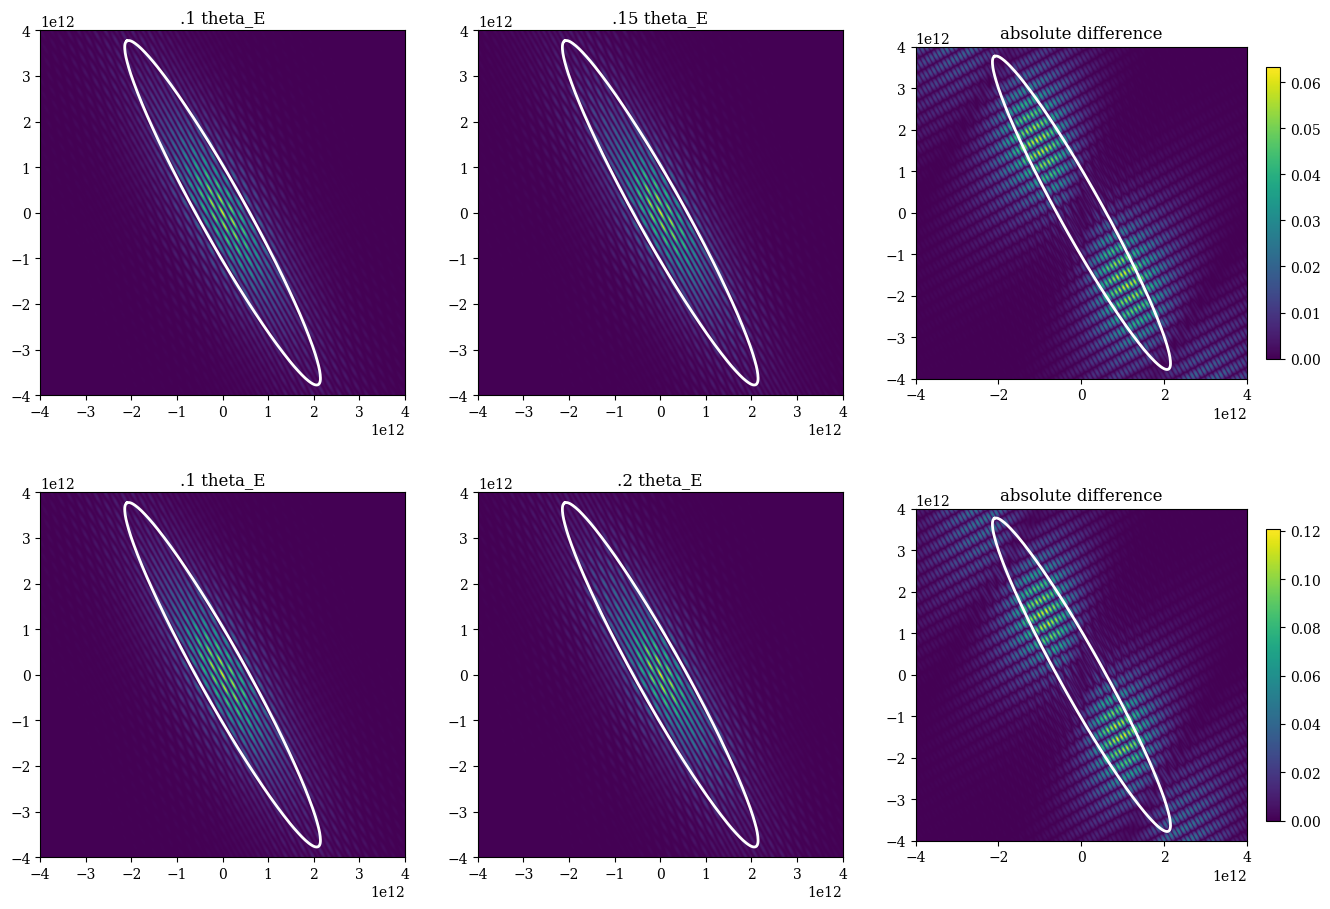

In [60]:
u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(image_size, d=theta_step))
extent = [u_vals[0], u_vals[-1], u_vals[0], u_vals[-1]]
plt.figure(figsize=(16, 11))
plt.subplot(2, 3, 1)
plt.title('.1 theta_E')

plt.imshow((corr_lensed), extent=extent, origin="lower", vmin=0, vmax=1, cmap="viridis")
plt.plot(2*ellipse[1, :], 2*ellipse[0, :], color='white', linewidth=2, label='Fitted ellipse')

plt.xlim(-4e12, 4e12);
plt.ylim(-4e12, 4e12);

plt.subplot(2, 3, 2)
plt.title('.15 theta_E')
plt.imshow((corr_lensed_2), extent=extent, origin="lower", vmin=0, vmax=1, cmap="viridis")
plt.plot(2*ellipse[1, :], 2*ellipse[0, :], color='white', linewidth=2, label='Fitted ellipse')

plt.xlim(-4e12, 4e12);
plt.ylim(-4e12, 4e12);

plt.subplot(2, 3, 3)
plt.title('absolute difference')
plt.imshow(np.abs(corr_lensed_2- corr_lensed), extent=extent, origin="lower", cmap="viridis")
plt.plot(2*ellipse[1, :], 2*ellipse[0, :], color='white', linewidth=2, label='Fitted ellipse')
plt.xlim(-4e12, 4e12);
plt.ylim(-4e12, 4e12);
plt.colorbar(fraction=.04);

### row 2, next image set  ###
plt.subplot(2, 3, 4)
plt.title('.1 theta_E')
plt.imshow((corr_lensed), extent=extent, origin="lower", vmin=0, vmax=1, cmap="viridis")
plt.plot(2*ellipse[1, :], 2*ellipse[0, :], color='white', linewidth=2, label='Fitted ellipse')

plt.xlim(-4e12, 4e12);
plt.ylim(-4e12, 4e12);

plt.subplot(2, 3, 5)
plt.title('.2 theta_E')
plt.imshow((corr_lensed_3), extent=extent, origin="lower", vmin=0, vmax=1, cmap="viridis")
plt.plot(2*ellipse[1, :], 2*ellipse[0, :], color='white', linewidth=2, label='Fitted ellipse')

plt.xlim(-4e12, 4e12);
plt.ylim(-4e12, 4e12);

plt.subplot(2, 3, 6)
plt.title('absolute difference')
plt.imshow(np.abs(corr_lensed_3- corr_lensed), extent=extent, origin="lower", cmap="viridis")
plt.plot(2*ellipse[1, :], 2*ellipse[0, :], color='white', linewidth=2, label='Fitted ellipse')
plt.xlim(-4e12, 4e12);
plt.ylim(-4e12, 4e12);
plt.colorbar(fraction=.04);

In [22]:
positions = place_star_radial(jnp.asarray(0.8), .1, image_size=image_size, phi_0=phi_0, angle=np.pi/3)# (positions_plot / (theta_step * image_size)) + 0.5
arr_rands = jnp.array([[(positions[0][0])*theta_step, (positions[0][1])*theta_step]])

M1 = 0.8 #* u.solMass.to(u.g)
star1 = [M1]
m_stars = [0.8]
star_params = (jnp.asarray(star1), D_s, D_l, D_ls, theta_max, arr_rands)
alpha_, beta_ = beta(g_params, star_params, arr_theta)
image_new, indices, vals = sparse_quasar_image(beta_, rad, theta_max, beta_min, quasar_int_sparse)
total_I_0=image_new.data.sum()
_,_,corr_lensed = calcC_sparse(image_new, theta_step, box_size=100, ellipse=False)

star_params = (jnp.asarray(0.82), D_s, D_l, D_ls, theta_max, arr_rands)
alpha_, beta_ = beta(g_params, star_params, arr_theta)
image_new2, indices, vals = sparse_quasar_image(beta_, rad, theta_max, beta_min, quasar_int_sparse)
_,_,corr_lensed_2 = calcC_sparse(image_new2, theta_step, box_size=100, ellipse=False)

NameError: name 'phi_0' is not defined

In [ ]:
samp_c1=corr_lensed[elps_pts]
samp_c2=corr_lensed_2[elps_pts]

In [ ]:
positions = place_star_radial(jnp.asarray(0.8), .1, image_size=image_size, phi_0=phi_0, angle=np.pi/3)# (positions_plot / (theta_step * image_size)) + 0.5
arr_rands = jnp.array([[(positions[0][0])*theta_step, (positions[0][1])*theta_step]])
masses=[.8, .82, .84, .86, .88, .90, .92]
amps_m=[]
tot_diff_m=[]
for mass in masses:
    M1 = mass
    star1 = [M1]
    star_params = (jnp.asarray(star1), D_s, D_l, D_ls, theta_max, arr_rands)
    alpha_, beta_ = beta(g_params, star_params, arr_theta)
    image_test, indices, vals = sparse_quasar_image(beta_, rad, theta_max, beta_min, quasar_int_sparse)
    _,_,corr_test = calcC_sparse(image_test, theta_step, box_size=100, ellipse=False)
    tot_diff_m.append(np.sum(np.abs(samp_c1-corr_test[elps_pts])))
    amps_m.append(np.max(samp_c1-corr_test[elps_pts]))

In [44]:
M1 = 0.8
star1 = [M1]
pos_fracs=[.1, .15, .2, .25, .3, .35, .4, .45]
amps_p=[]
tot_diff_p=[]

for pos_frac in pos_fracs:
    positions = place_star_radial(jnp.asarray(0.8), pos_frac, image_size=image_size, phi_0=phi_0, angle=np.pi/3)# (positions_plot / (theta_step * image_size)) + 0.5
    arr_rands = jnp.array([[(positions[0][0])*theta_step, (positions[0][1])*theta_step]])
    star_params = (jnp.asarray(star1), D_s, D_l, D_ls, theta_max, arr_rands)
    alpha_, beta_ = beta(g_params, star_params, arr_theta)
    image_test, indices, vals = sparse_quasar_image(beta_, rad, theta_max, beta_min, quasar_int_sparse)
    _,_,corr_test = calcC_sparse(image_test, theta_step, box_size=100, ellipse=False)
    tot_diff_p.append(np.sum(np.abs(samp_c1-corr_test[elps_pts])))
    amps_p.append(np.max(samp_c1-corr_test[elps_pts]))

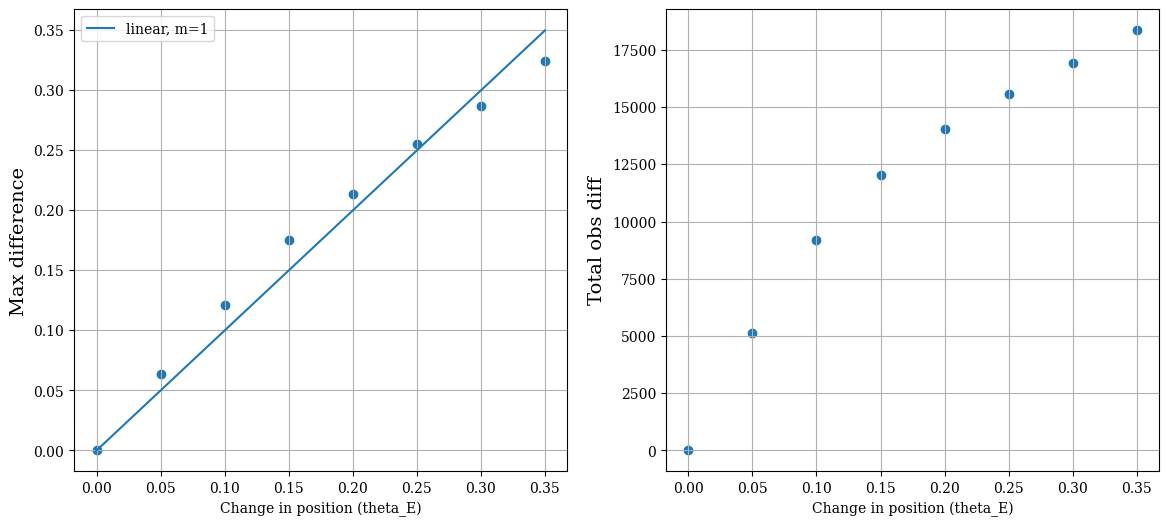

In [54]:
pos_fracs=np.array(pos_fracs)
xplot=pos_fracs-.1
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.scatter(xplot, amps_p)
plt.plot(xplot, xplot, label='linear, m=1')
plt.ylabel('Max difference', fontsize=14)
plt.xlabel('Change in position (theta_E)')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(xplot, tot_diff_p)
plt.ylabel('Total obs diff', fontsize=14)
plt.xlabel('Change in position (theta_E)')
plt.grid()


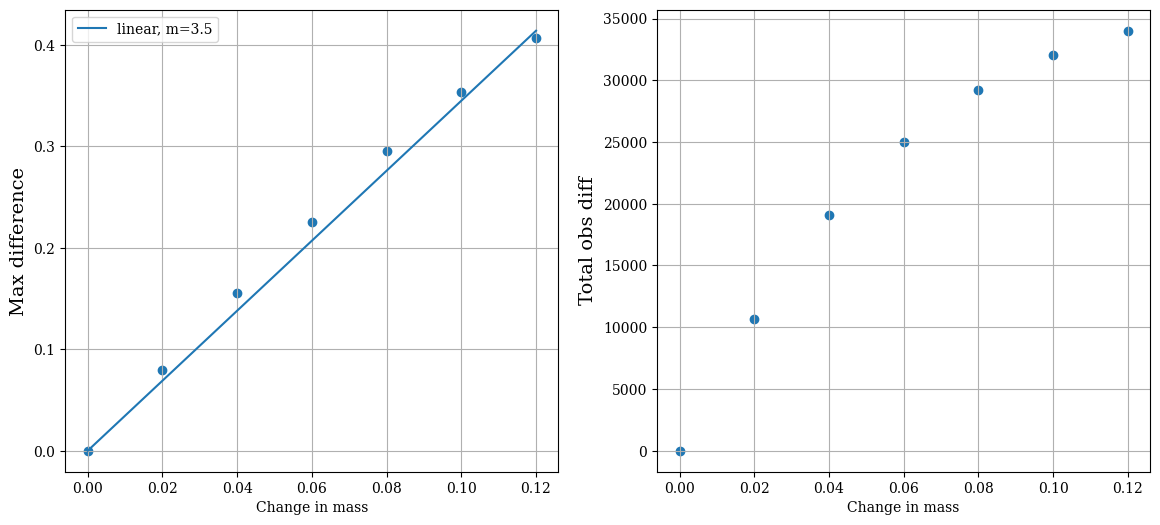

In [55]:
masses=np.array(masses)
xplot=masses-.8
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.scatter(xplot, amps_m)
plt.plot(xplot, xplot*3.45, label='linear, m=3.5')
plt.ylabel('Max difference', fontsize=14)
plt.xlabel('Change in mass')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(xplot, tot_diff_m)
plt.ylabel('Total obs diff', fontsize=14)
plt.xlabel('Change in mass')
plt.grid()


### paper figures

In [22]:
#regenerate unlensed image, not strictly necessary
image_size = int(8000) # number of pixels
N_step = image_size
theta_max = 2e-10 # (half) size of image
theta_step = 2 * theta_max / image_size
vec_theta = jnp.linspace(-theta_max, theta_max, N_step)
arr_theta = jnp.asarray(jnp.meshgrid(vec_theta, vec_theta, indexing='xy'))
rad = theta_500 
arr_rands = jnp.array([[(300-239), (500-68)]])
m_stars = jnp.asarray([0.4])
positions = place_star_radial(m_stars, 0, image_size=image_size)

#unlensed image
alpha_0, beta_0 = beta(g_params, (jnp.asarray(0), D_s, D_l, D_ls, theta_max, arr_rands), arr_theta)
pad_frac=0
beta_min = 100e-11 #get full image this time, don't do this when actually computing derived quantities
image_0, _,_ = sparse_quasar_image(beta_0, rad, theta_max, beta_min, quasar_int_sparse)
u_full,v_full, corr_0_full=calcC_sparse(image_0, theta_step, ellipse=False)
upts_8k, vpts_8k, corr_0 = calcC_sparse(image_0, theta_step, ellipse=True)
elps_pts=jnp.asarray((vpts_8k, upts_8k)) #reversed again, as we do in the corr_C function
corr_0=corr_0_full[vpts_8k, upts_8k]

In [24]:
## lensed image
arr_rands=(jnp.array([[4010], [4200]])*theta_step).reshape(1,2) #semi-random location, just illustrative
star_params_1 = (m_stars, D_s, D_l, D_ls, theta_max, arr_rands)
_, beta_1 = beta(g_params, star_params_1, arr_theta)
image_1, _, _=sparse_quasar_image(beta_1, theta_500, theta_max, beta_min, quasar_int_sparse)
_,_, corr_1_full=calcC_sparse(image_1, theta_step, ellipse=False)
corr_1=corr_1_full[vpts_8k, upts_8k]

#fully unlensed (not even macrolensing)
alpha_00, beta_00 = beta((0,0,0), (jnp.asarray(0), D_s, D_l, D_ls, theta_max, arr_rands), arr_theta)
image_00, _, _= sparse_quasar_image(beta_00, rad, theta_max, beta_min, quasar_int_sparse)
u_full,v_full, corr_00_full=calcC_sparse(image_00, theta_step, ellipse=False)

In [25]:
# Convert sparse matrices to dense arrays for plotting
im_00 = np.log(image_00.todense()+1e-40)
im_0  = np.log(image_0.todense()+1e-40)
im_1  = np.log(image_1.todense()+1e-40)
u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(image_size, d=theta_step))
umax=np.max(u_vals)
max_x = 10*(np.array(place_star_radial(jnp.asarray(0.4), 10.2, angle=0,
                        image_size=image_size, phi_0=phi_0, theta_max=theta_max))/image_size-0.5)*theta_step*image_size

/mnt/home/amoran/lensing/Figures/basic_lensing.pdf

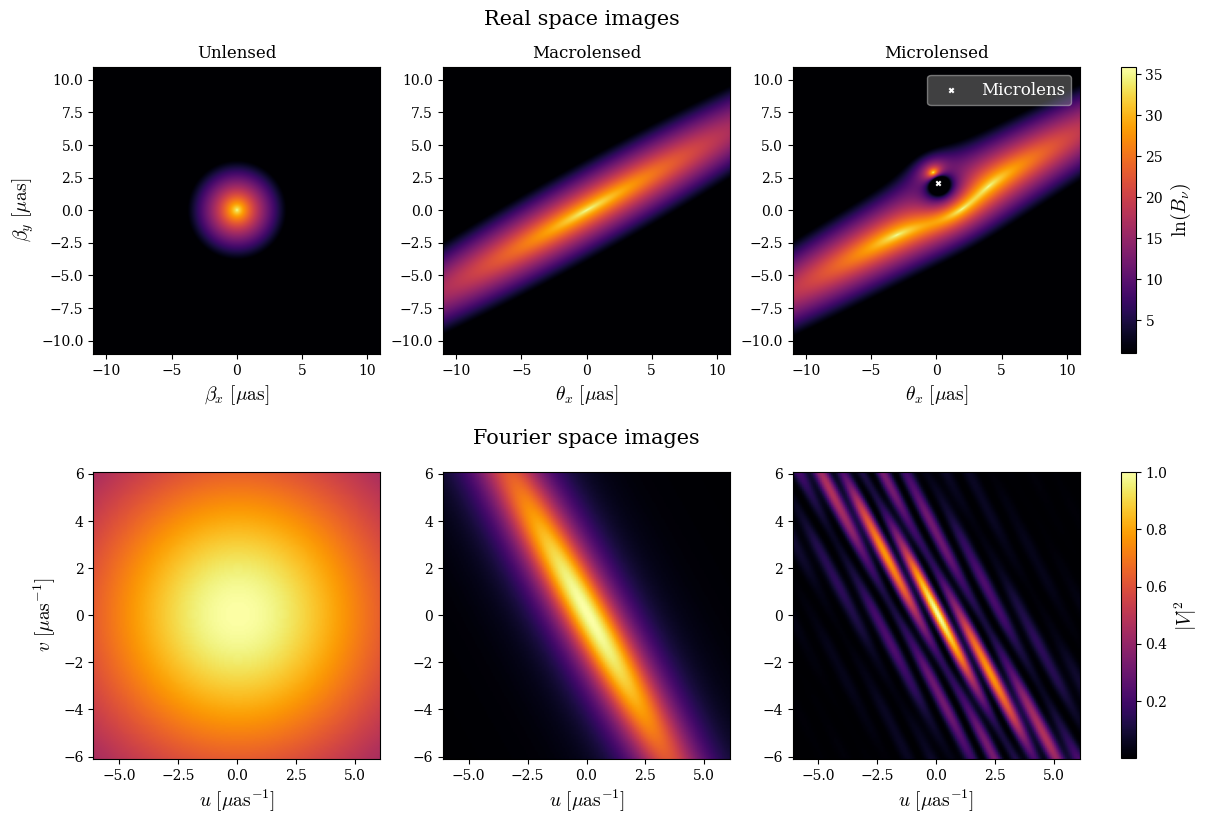

In [33]:
#Generate Figure 1

zoom = 50
ny, nx = corr_00_full.shape
cy, cx = ny//2, nx//2  # center
def zoom_in(arr, factor=zoom):
    half_y = ny // (2*factor)
    half_x = nx // (2*factor)
    return arr[cy-half_y:cy+half_y, cx-half_x:cx+half_x]

corr_00_z = zoom_in(corr_00_full)
corr_0_z  = zoom_in(corr_0_full)
corr_1_z  = zoom_in(corr_1_full)

# Make the figure
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
fig.text(0.48, 1.019, r'Real space images', ha='center', va='top', fontsize=15, transform=fig.transFigure)
imlist = [im_00, im_0, im_1]
titles = [r"Unlensed", r"Macrolensed", r"Microlensed"]
vmin = 1 
vmax = max(im.max() for im in imlist)
for i, ax in enumerate(axes[0]):
    implot = ax.imshow(imlist[i], origin="lower", extent=[-theta_max*rad_to_arcsec, theta_max*rad_to_arcsec, -theta_max*rad_to_arcsec, theta_max*rad_to_arcsec], 
                       vmin=vmin, vmax=vmax, cmap="inferno")
    ax.set_xlabel(r"$\theta_x \ [\mu \text{as}]$", fontsize=14)
    if i == 0:
        ax.set_ylabel(r"$\theta_y \ [\mu \text{as}]$", fontsize=14)
    if i ==1:
        ax.plot((0, max_x[0][0]), (0,max_x[0][1]), color='white', linestyle='--')
        ax.plot((0, -max_x[0][0]), (0, -max_x[0][1]), color='white', linestyle='--')

    ax.set_title(titles[i])
    ax.set_xlim(-11, 11)
    ax.set_ylim(-11, 11)
cbar1 = fig.colorbar(implot, ax=axes[0, :], location="right", fraction=0.0145, pad=0.04)
cbar1.set_label(r"$\ln(B_\nu)$", fontsize=14)

imlist2 = [corr_00_z, corr_0_z, corr_1_z]
titles2 = [r"$|V_{00}|^2$", r"$|V_{0}|^2$", r"$|V_{1}|^2$"]
vmin2 = min(im.min() for im in imlist2)
vmax2 = max(im.max() for im in imlist2)
extent_z =np.array( [-umax/zoom, umax/zoom, -umax/zoom, umax/zoom])/rad_to_arcsec
#extent_z=[-umax/zoom*2, umax/zoom*2, -umax/zoom*2, umax/zoom*2]
for i, ax in enumerate(axes[1]):
    implot2 = ax.imshow(imlist2[i], origin="lower", extent=extent_z, vmin=vmin2, vmax=vmax2, cmap="inferno")
    ax.set_xlabel(r"$u \ [\mu \text{as}^{-1}]$", fontsize=14)
    if i == 0:
        ax.set_ylabel(r"$v \ [\mu \text{as}^{-1}]$", fontsize=14)
        
    #ax.set_title(titles2[i])
cbar2 = fig.colorbar(implot2, ax=axes[1, :], location="right", fraction=0.0145, pad=0.04)
cbar2.set_label(r"$|V|^2$", fontsize=14)
axes[1, 1].set_title("Fourier space images", fontsize=15, pad=20)

axes[0, 0].set_xlabel(r"$\beta_x \ [\mu \text{as}]$", fontsize=14)
axes[0, 0].set_ylabel(r"$\beta_y \ [\mu \text{as}]$", fontsize=14)
axes[0,2].scatter((arr_rands[0][0]-2e-10)*rad_to_arcsec, (arr_rands[0][1]-2e-10)*rad_to_arcsec, color='white', marker='x', s=10, label='Microlens')
axes[0,2].legend(fontsize=12, facecolor='gray', framealpha=.5,  labelcolor='white')
#plt.show()

#plt.savefig('Figures/basic_lensing.pdf', bbox_inches='tight')
#FileLink('Figures/basic_lensing.pdf')



In [26]:
## generate a second microlensed image at a more distance point for illustrative purposes in the appendix
m_stars = jnp.asarray([0.4])
arr_rands_far=(jnp.array([[4020], [4400]])*theta_step).reshape(1,2)
#arr_rands = jnp.array([[(positions[i][0])*theta_step, (positions[i][1])*theta_step]])
star_params_far = (m_stars, D_s, D_l, D_ls, theta_max, arr_rands_far)
_, beta_far = beta(g_params, star_params_far, arr_theta)
image_far, _, _=sparse_quasar_image(beta_far, theta_500, theta_max, beta_min, quasar_int_sparse)
_,_, corr_far_full=calcC_sparse(image_far, theta_step, ellipse=False)

corr_far=corr_far_full[vpts_8k, upts_8k] #this is the observations we'd actually see, not really necessary here
image_far = np.log(image_far.todense()+1e-40)

## lensed image - similar to above but iwht a more massive lens
m_stars = jnp.asarray([1.])
arr_rands=(jnp.array([[4010], [4200]])*theta_step).reshape(1,2)
star_params_mass = (m_stars, D_s, D_l, D_ls, theta_max, arr_rands)
_, beta_mass = beta(g_params, star_params_mass, arr_theta)
image_mass, _, _=sparse_quasar_image(beta_mass, theta_500, theta_max, beta_min, quasar_int_sparse)
_,_, corr_mass_full=calcC_sparse(image_mass, theta_step, ellipse=False)


corr_mass=corr_mass_full[vpts_8k, upts_8k] #these are the points we'd actually see, not really necessary here
image_mass = np.log(image_mass.todense()+1e-40) # add floor for plotting purposes

<>:19: SyntaxWarning: invalid escape sequence '\,'
<>:20: SyntaxWarning: invalid escape sequence '\,'
<>:21: SyntaxWarning: invalid escape sequence '\,'
<>:19: SyntaxWarning: invalid escape sequence '\,'
<>:20: SyntaxWarning: invalid escape sequence '\,'
<>:21: SyntaxWarning: invalid escape sequence '\,'
/tmp/ipykernel_1790498/474278303.py:19: SyntaxWarning: invalid escape sequence '\,'
  titles = [f'$m_l=0.4M_\\odot$, $\\theta_{{\\rm sep}}={theta_close:.2f} \, \\mu $as',
/tmp/ipykernel_1790498/474278303.py:20: SyntaxWarning: invalid escape sequence '\,'
  f'$m_l=0.4M_\\odot$, $\\theta_{{\\rm sep}}={theta_far:.2f} \, \\mu $as',
/tmp/ipykernel_1790498/474278303.py:21: SyntaxWarning: invalid escape sequence '\,'
  f'$m_l=1.0M_\\odot$, $\\theta_{{\\rm sep}}={theta_close:.2f} \, \\mu $as']


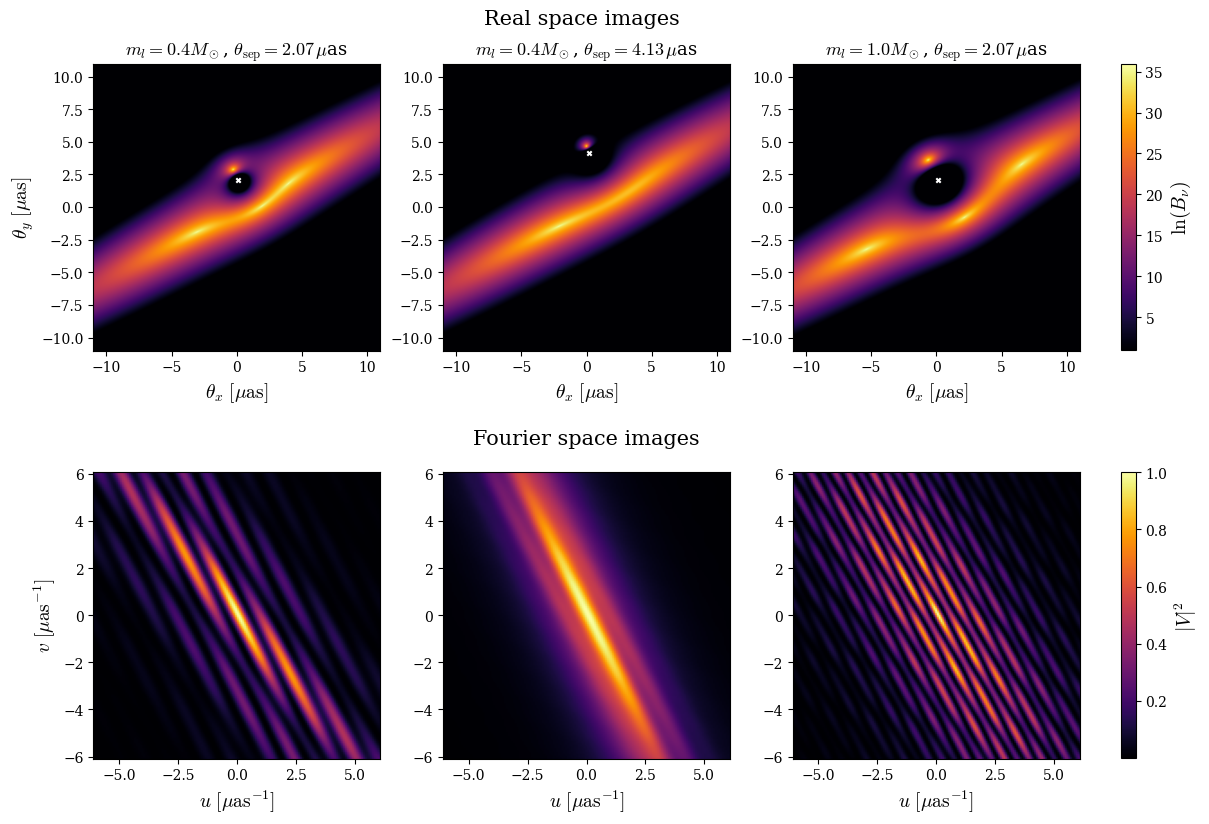

In [27]:
zoom = 50
ny, nx = corr_1_full.shape
cy, cx = ny//2, nx//2  # center
def zoom_in(arr, factor=zoom):
    half_y = ny // (2*factor)
    half_x = nx // (2*factor)
    return arr[cy-half_y:cy+half_y, cx-half_x:cx+half_x]

corr_far_z = zoom_in(corr_far_full)
corr_mass_z  = zoom_in(corr_mass_full)
corr_1_z  = zoom_in(corr_1_full)

# Make the figure
fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
fig.text(0.48, 1.022, r'Real space images', ha='center', va='top', fontsize=15, transform=fig.transFigure)
imlist = [im_1, image_far, image_mass]
theta_close=(np.linalg.norm(arr_rands-2e-10))*rad_to_arcsec
theta_far= (np.linalg.norm(arr_rands_far-2e-10))*rad_to_arcsec
titles = [f'$m_l=0.4M_\\odot$, $\\theta_{{\\rm sep}}={theta_close:.2f} \, \\mu $as',
          f'$m_l=0.4M_\\odot$, $\\theta_{{\\rm sep}}={theta_far:.2f} \, \\mu $as', 
          f'$m_l=1.0M_\\odot$, $\\theta_{{\\rm sep}}={theta_close:.2f} \, \\mu $as']

vmin = 1#min(im.min() for im in imlist)
vmax = max(im.max() for im in imlist)
for i, ax in enumerate(axes[0]):
    implot = ax.imshow(imlist[i], origin="lower", extent=[-theta_max*rad_to_arcsec, theta_max*rad_to_arcsec, -theta_max*rad_to_arcsec, theta_max*rad_to_arcsec], 
                       vmin=vmin, vmax=vmax, cmap="inferno")
    ax.set_xlabel(r"$\theta_x \ [\mu \text{as}]$", fontsize=14)
    if i == 0:
        ax.set_ylabel(r"$\theta_y \ [\mu \text{as}]$", fontsize=14)
    
    ax.set_title(titles[i], fontsize=13)
    ax.set_xlim(-11, 11)
    ax.set_ylim(-11, 11)
cbar1 = fig.colorbar(implot, ax=axes[0, :], location="right", fraction=0.0145, pad=0.04)
cbar1.set_label(r"$\ln(B_\nu)$", fontsize=14)
#axes[0, 1].set_title("Real space images", fontsize=14, pad=20)

imlist2 = [corr_1_z, corr_far_z, corr_mass_z]
titles2 = [r"$|V_{00}|^2$", r"$|V_{0}|^2$", r"$|V_{1}|^2$"]
vmin2 = min(im.min() for im in imlist2)
vmax2 = max(im.max() for im in imlist2)
extent_z =np.array( [-umax/zoom, umax/zoom, -umax/zoom, umax/zoom])/rad_to_arcsec
for i, ax in enumerate(axes[1]):
    implot2 = ax.imshow(imlist2[i], origin="lower", extent=extent_z, vmin=vmin2, vmax=vmax2, cmap="inferno")
    ax.set_xlabel(r"$u \ [\mu \text{as}^{-1}]$", fontsize=14)
    if i == 0:
        ax.set_ylabel(r"$v \ [\mu \text{as}^{-1}]$", fontsize=14)
        
    #ax.set_title(titles2[i])
cbar2 = fig.colorbar(implot2, ax=axes[1, :], location="right", fraction=0.0145, pad=0.04)
cbar2.set_label(r"$|V|^2$", fontsize=14)
axes[1, 1].set_title("Fourier space images", fontsize=15, pad=20)

axes[0,0].scatter((arr_rands[0][0]-2e-10)*rad_to_arcsec, (arr_rands[0][1]-2e-10)*rad_to_arcsec, color='white', marker='x', s=10)
axes[0,1].scatter((arr_rands_far[0][0]-2e-10)*rad_to_arcsec, (arr_rands_far[0][1]-2e-10)*rad_to_arcsec, color='white', marker='x', s=10)
axes[0,2].scatter((arr_rands[0][0]-2e-10)*rad_to_arcsec, (arr_rands[0][1]-2e-10)*rad_to_arcsec, color='white', marker='x', s=10)

#axes[0,2].legend(fontsize=12)
#plt.show()

#plt.savefig('Figures/lensing_comparison.pdf', bbox_inches='tight')
#FileLink('Figures/lensing_comparison.pdf')



In [28]:
# generate sampling points for illustrative purposes, far fewer points than we really use
u_vals = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(image_size, d=theta_step))/rad_to_arcsec
umax=np.max(u_vals)
a, b, phi, corr_pts=get_uv_elipse(corr_0_full, u_vals, u_vals, numpts=500)

/mnt/home/amoran/lensing/Figures/sampling.pdf

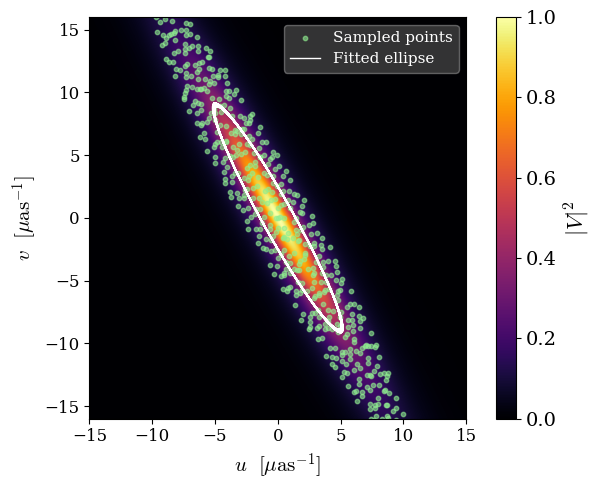

In [43]:
# plot the poitns over the quasar image in Fourier space 
fig, ax = plt.subplots(figsize=(7, 5))
    
# Show correlation function

extent =np.array( [-umax, umax, -umax, umax])
im=ax.imshow(corr_0_full, origin="lower", extent=extent, vmin=0, vmax=1, cmap="inferno")
cbar = plt.colorbar(im, ax=ax, fraction=.046)
cbar.set_label(r"$|V|^2$", fontsize=16)
cbar.ax.tick_params(labelsize=14)
ax.scatter(corr_pts[:, 1].T, corr_pts[:, 0].T, color='lightgreen', s=10, alpha=0.6, label='Sampled points')

# Plot ellipse boundary
t = np.linspace(0, 2*np.pi, 300)*rad_to_arcsec
ellipse_u = a * np.cos(t)
ellipse_v = b * np.sin(t)

rot = np.array([[np.cos(phi), -np.sin(phi)],
                [np.sin(phi),  np.cos(phi)]])
ellipse = rot @ np.vstack([ellipse_u, ellipse_v])
ax.plot(ellipse[1, :], ellipse[0, :], color='white', linewidth=1, label='Fitted ellipse')

ax.plot((0, 1*max_x[0][0]), (0, 1*max_x[0][1]), color='white', linestyle='--') #keep same angle just scale it up like crazy 
ax.plot((0, -1*max_x[0][0]), (0, -1*max_x[0][1]), color='white', linestyle='--') 

ax.set_xlabel(r"$u\ \ [\mu \text{as}^{-1}]$", fontsize=15)
ax.set_ylabel(r"$v\ \ [\mu \text{as}^{-1}]$", fontsize=15)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.tick_params(axis='both', which='minor', labelsize=10)

ax.set_ylim(-19, 19)
ax.set_xlim(-12, 12)
ax.set_aspect('equal')
ax.legend(fontsize=11, labelcolor='white', facecolor='gray', framealpha=0.4)
plt.tight_layout()
#plt.show()
#plt.savefig('Figures/sampling.pdf', bbox_inches='tight')
#FileLink('Figures/sampling.pdf')


In [27]:
factor = 50  # zoom factor

# Find the center
ny, nx = corr_0_full.shape
cy, cx = ny // 2, nx // 2

# Size of the zoomed region (keep factor in mind)
half_size_y = ny // (2*factor)
half_size_x = nx // (2*factor)

# Crop central region
cropped0 = corr_0_full[cy-half_size_y:cy+half_size_y,
                       cx-half_size_x:cx+half_size_x]
cropped1 = corr_1_full[cy-half_size_y:cy+half_size_y,
                       cx-half_size_x:cx+half_size_x]

In [125]:
data0 = center_data(cropped0)
#data = data.reshape(1, -1)  # shape (1, num_points)

cov_matrix0 = compute_covariance_matrix(data0)
eigenvalues0, eigenvectors0 = compute_principal_components(cov_matrix0)
#largest_indices, largest_features = get_largest_coefficients(eigenvectors)

In [126]:
data1 = center_data(cropped1)
#data = data.reshape(1, -1)  # shape (1, num_points)

cov_matrix1 = compute_covariance_matrix(data1)
eigenvalues1, eigenvectors1 = compute_principal_components(cov_matrix1)
#largest_indices, largest_features = get_largest_coefficients(eigenvectors)

Text(0, 0.5, 'Eigenvalue')

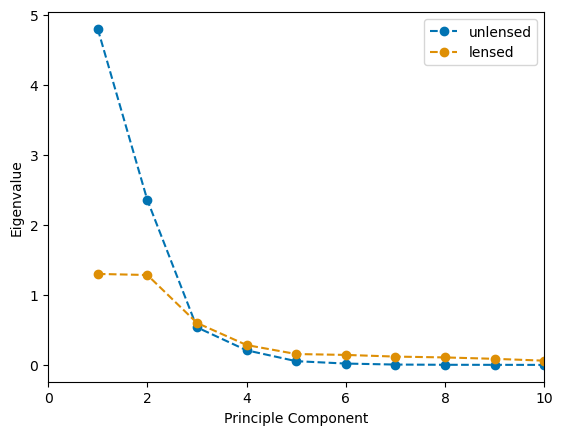

In [127]:
plt.plot(np.array(range(len(eigenvalues0)))+1, np.sort(eigenvalues0)[::-1], linestyle='--', marker='o', label='unlensed')
plt.plot(np.array(range(len(eigenvalues1)))+1, np.sort(eigenvalues1)[::-1], linestyle='--', marker='o', label='lensed')
plt.legend()
plt.xlim(0,10)
plt.xlabel('Principle Component')
plt.ylabel('Eigenvalue')

In [128]:
def fraction_top_variance(eigenvalues, eig_errs, k_start=1, k_stop=10):
    top_sum = np.sum(eigenvalues[:k_start])
    total_sum = np.sum(eigenvalues[:k_stop])
    H = top_sum / total_sum

    derivs = np.zeros_like(eigenvalues[:k_stop])
    derivs[:k_start] = 1 / total_sum
    derivs[k_start:k_stop] = -top_sum / (total_sum**2)

        # Propagate errors
    H_err = np.sqrt(np.sum((derivs * eig_errs[:k_stop])**2))
    return H, H_err


In [130]:
print(fraction_top_variance(jnp.real(eigenvalues1), np.zeros_like(eigenvalues1)))


(Array(0.31392692, dtype=float64), np.complex128(0j))


In [131]:
eigvals, eigvecs = np.linalg.eigh(cov_matrix0)
eigvals = np.sort(eigvals)[::-1]
eigvecs = eigvecs[:, ::-1]

eig_errs = sigma_C * np.sqrt(np.sum(eigvecs**4, axis=0)) #we have order 10^4 pts, so full sigma_C value

In [132]:
print(fraction_top_variance(jnp.real(eigenvalues0), eig_errs))

(Array(0.60144285, dtype=float64), np.float64(0.2789450984364956))


#### Check $\chi^2$ behaves as we would expect

In [179]:
def chi2(data, unlensed, error):
    return jnp.sum((data-unlensed)**2/error**2)

Chi^2 as a function of lens distance to see where we can ID microlensing with a single observation. This is just a check that this is behaving as we would expect, and is an intermediate result

In [19]:
# 0.4 solar masses
m_stars = jnp.asarray([0.4])
m_stars_1 = jnp.asarray([1.0])

fracs=[0, .1, .2, .4, .6, .7, .8,.9, 1,1.1, 1.2, 1.3, 1.4, 1.45, 1.5,1.55, 1.6,1.65, 1.7, 1.75, 1.8,1.9, 2, 2.1]
chi2s_04=[]
chi2s_10=[]
for frac in fracs:
    positions = place_star_radial(m_stars, frac, image_size=image_size)# (positions_plot / (theta_step * image_size)) + 0.5
    positions_1 = place_star_radial(m_stars_1, frac, image_size=image_size)
    arr_rands = jnp.array([[(positions[0][0])*theta_step, (positions[0][1])*theta_step]])
    arr_rands_1 = jnp.array([[(positions_1[0][0])*theta_step, (positions_1[0][1])*theta_step]])

    star_params_4 = (m_stars, D_s, D_l, D_ls, theta_max, arr_rands)
    star_params_1 = (m_stars_1, D_s, D_l, D_ls, theta_max, arr_rands_1)

    _, beta_1 = beta(g_params, star_params_1, arr_theta)
    image_1, _, _=sparse_quasar_image(beta_1, theta_500, theta_max, beta_min, quasar_int_sparse)
    _,_, corr_here1_full=calcC_sparse(image_1, theta_step, ellipse=False)
    corr_here1=corr_here1_full[vpts_8k, upts_8k]
    chi2s_10.append(chi2(corr_here1, corr_0, (sigma_C/np.sqrt(10))))

    _, beta_4 = beta(g_params, star_params_4, arr_theta)
    image_4, _, _=sparse_quasar_image(beta_4, theta_500, theta_max, beta_min, quasar_int_sparse)
    _,_, corr_here_full=calcC_sparse(image_4, theta_step, ellipse=False)
    corr_here=corr_here_full[vpts_8k, upts_8k]
    chi2s_04.append(chi2(corr_here, corr_0, (sigma_C/np.sqrt(10))))

/mnt/home/amoran/lensing/Figures/chi2_M04.pdf

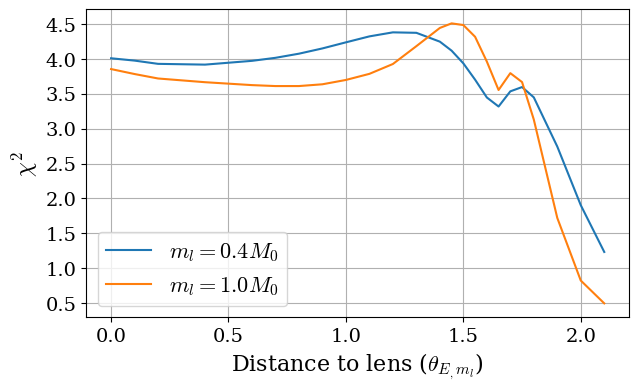

In [32]:
plt.figure(figsize=(7,4))
plt.plot(fracs, chi2s_04, label=r'$m_l=0.4 M_0$')
plt.plot(fracs, chi2s_10, label=r'$m_l=1.0 M_0$')

plt.grid()
plt.xlabel(r'Distance to lens ($\theta_{E_,m_l}$)',  fontsize=16)
plt.ylabel(r'$\chi^2$', fontsize=17)
#plt.title(r'$m_l=0.4 M_0$')
plt.legend(fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

#plt.savefig('Figures/chi2_M04.pdf', bbox_inches='tight')
#FileLink('Figures/chi2_M04.pdf')

Now as a function of mass for a set source-lens separation

In [35]:
# close
masses=np.linspace(.01, .3, 21) #[.05, .1, .2,.3, .4]
positions = place_star_radial(0.4, .2, image_size=image_size)# (positions_plot / (theta_step * image_size)) + 0.5
arr_rands = jnp.array([[(positions[0][0])*theta_step, (positions[0][1])*theta_step]])

chi2s_close=[]
for mass in masses:
    m_stars = jnp.asarray([mass])
    #positions = place_star_radial(m_stars, .2, image_size=image_size)# (positions_plot / (theta_step * image_size)) + 0.5
    #arr_rands = jnp.array([[(positions[0][0])*theta_step, (positions[0][1])*theta_step]])
    star_params_1 = (m_stars, D_s, D_l, D_ls, theta_max, arr_rands)
    _, beta_1 = beta(g_params, star_params_1, arr_theta)
    image_1, _, _=sparse_quasar_image(beta_1, theta_500, theta_max, beta_min, quasar_int_sparse)
    _,_, corr_here_full=calcC_sparse(image_1, theta_step, ellipse=False)
    corr_here=corr_here_full[vpts_8k, upts_8k]
    chi2s_close.append(chi2(corr_here, corr_0, (sigma_C/np.sqrt(10))))

(0.0, 0.3)

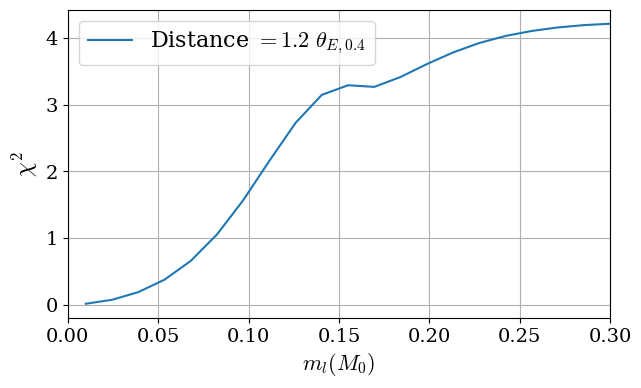

In [182]:
plt.figure(figsize=(7,4))
#plt.plot(masses, chi2s_close, label=r'Distance $=0.2 \ \theta_{E, 0.4}$')
plt.plot(masses_f, chi2s_far, label=r'Distance $=1.2 \ \theta_{E, 0.4}$')

plt.grid()
plt.xlabel(r'$m_l (M_0)$', fontsize=16)
plt.ylabel(r'$\chi^2$', fontsize=17)
plt.legend(fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0, .3) 
#plt.title(r'Lens distance $=0.4 \ \theta_{E_{0.4}}$')

#plt.savefig('Figures/chi2_close.pdf', bbox_inches='tight')
#FileLink('Figures/chi2_close.pdf')